# Module II (completed): convolutional autoencoder, VAE and GAN
All three on MNIST, trained on a Kaggle GPU (`kaggle/syllabus/run_syllabus.py`). Numbers below are read from `report/syllabus_results/`; the written analysis is in `report/SYLLABUS.md`.

In [1]:
import sys, os, json, inspect
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
import numpy as np, matplotlib.pyplot as plt, matplotlib.image as mpimg
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
res = lambda n: json.load(open(ROOT / "report" / "syllabus_results" / f"{n}.json"))
def show(name, width=15):
    img = mpimg.imread(ROOT / "report" / "figures" / f"syllabus_{name}.png")
    plt.figure(figsize=(width, width * img.shape[0] / img.shape[1])); plt.imshow(img); plt.axis("off"); plt.show()


## Convolutional autoencoder
The model, then the bottleneck study and the denoising result.

In [2]:
from src.syllabus.ae import ConvAE
print(inspect.getsource(ConvAE))
print('parameters for z = 2, 8, 32:', [sum(p.numel() for p in ConvAE(z).parameters()) for z in (2, 8, 32)])

class ConvAE(nn.Module):
    """28x28 -> 14 -> 7 -> latent vector -> 7 -> 14 -> 28. The decoder returns logits (the loss is binary cross-entropy)."""

    def __init__(self, latent: int):
        super().__init__()
        self.latent = latent
        self.enc = nn.Sequential(nn.Conv2d(1, 16, 3, 2, 1), nn.ReLU(inplace=True), nn.Conv2d(16, 32, 3, 2, 1), nn.ReLU(inplace=True),
                                 nn.Flatten(), nn.Linear(32 * 49, latent))
        self.dec_fc = nn.Sequential(nn.Linear(latent, 32 * 49), nn.ReLU(inplace=True))
        self.dec = nn.Sequential(nn.ConvTranspose2d(32, 16, 3, 2, 1, output_padding=1), nn.ReLU(inplace=True),
                                 nn.ConvTranspose2d(16, 1, 3, 2, 1, output_padding=1))

    def encode(self, x):
        return self.enc(x)

    def decode(self, z):
        return self.dec(self.dec_fc(z).view(-1, 32, 7, 7))

    def forward(self, x):
        z = self.encode(x)
        return self.decode(z), z

parameters for z = 2, 8, 32: [17411,

z= 2  compression  392.0x   held-out MSE 0.0448
z= 8  compression   98.0x   held-out MSE 0.0182
z=32  compression   24.5x   held-out MSE 0.0045
denoising (noise std 0.5): {'denoising_ae_mse_on_noisy_input': 0.0119, 'plain_ae_mse_on_noisy_input': 0.089, 'mse_of_the_noisy_image_itself': 0.1157}


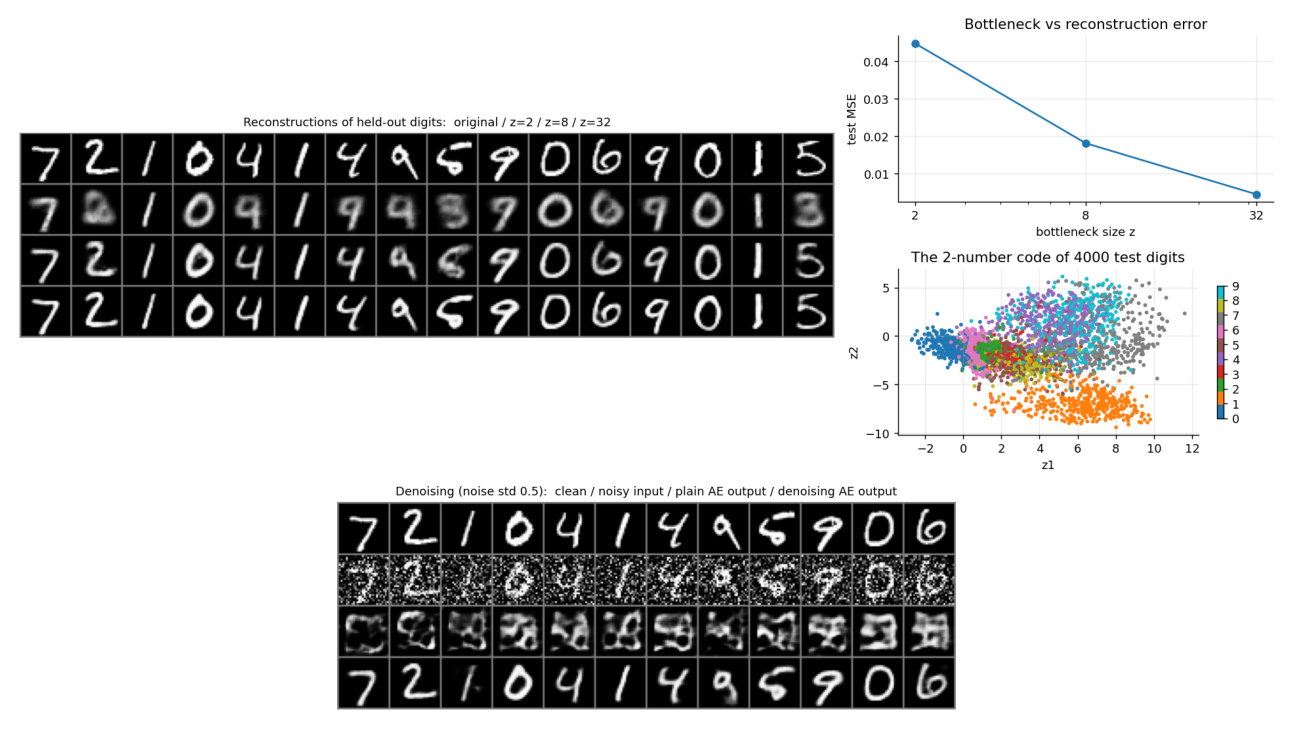

In [3]:
a = res('ae')
for z, r in a['bottleneck'].items(): print(f"z={z:>2}  compression {r['compression']:>6}x   held-out MSE {r['test_mse']:.4f}")
print('denoising (noise std 0.5):', {k: round(v, 4) for k, v in a['denoising'].items() if k != 'noise_std'})
show('ae')

## Variational autoencoder
The loss is where it differs from the plain AE: reconstruction plus a KL term that keeps the code close to N(0, I).

In [4]:
from src.syllabus.vae import ConvVAE, loss_terms
print(inspect.getsource(loss_terms)); print(inspect.getsource(ConvVAE.forward))

def loss_terms(logits, x, mu, logvar):
    """Per-image reconstruction (BCE summed over pixels, nats) and KL(q(z|x) || N(0, I)) (nats), averaged over the batch."""
    recon = F.binary_cross_entropy_with_logits(logits, x, reduction="sum") / x.size(0)
    kl = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / x.size(0)
    return recon, kl

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = mu + torch.randn_like(mu) * torch.exp(0.5 * logvar)
        return self.decode(z), mu, logvar



run              recon      KL    -ELBO  active dims
z2_beta1         149.2     5.9    155.1       2 / 2
z16_beta1         77.6    23.9    101.5      16 / 16
z16_beta0.1       67.5    47.5    114.9      16 / 16
z16_beta4        106.4    10.2    116.7      16 / 16


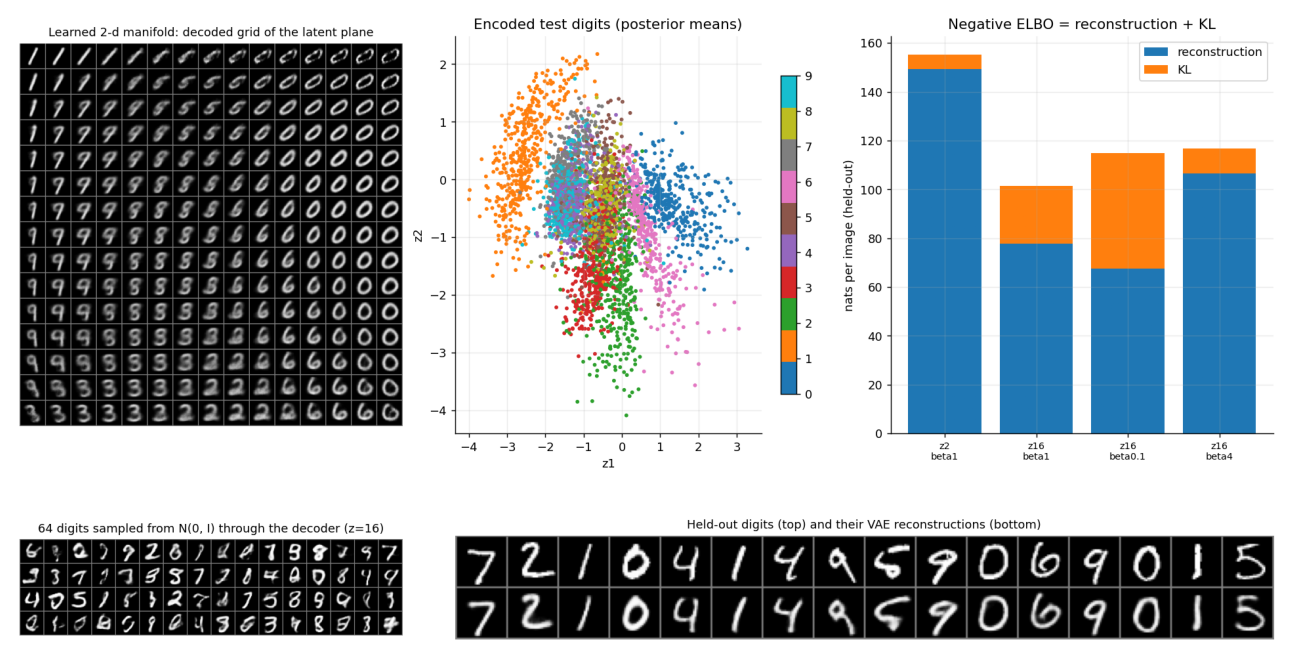

In [5]:
v = res('vae')
print(f"{'run':<14}{'recon':>8}{'KL':>8}{'-ELBO':>9}{'active dims':>13}")
for name, r in v['runs'].items(): print(f"{name:<14}{r['recon']:>8.1f}{r['kl']:>8.1f}{r['neg_elbo']:>9.1f}{r['active_dims']:>8} / {r['latent']}")
show('vae')

## GAN (DCGAN)
Judged with the digit CNN from the Module III notebook: classifier confidence, class entropy (mode coverage) and an Inception-style score.

In [6]:
from src.syllabus.gan import Generator, Discriminator
print(inspect.getsource(Generator)); print('G params', sum(p.numel() for p in Generator().parameters()), ' D params', sum(p.numel() for p in Discriminator().parameters()))

class Generator(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc = nn.Sequential(nn.Linear(ZDIM, 128 * 7 * 7, bias=False), nn.BatchNorm1d(128 * 7 * 7), nn.ReLU(inplace=True))
        self.net = nn.Sequential(nn.ConvTranspose2d(128, 64, 4, 2, 1, bias=False), nn.BatchNorm2d(64), nn.ReLU(inplace=True),
                                 nn.ConvTranspose2d(64, 1, 4, 2, 1), nn.Tanh())

    def forward(self, z):
        return self.net(self.fc(z).view(-1, 128, 7, 7))          # in [-1, 1]

G params 771969  D params 138689


real_test       {'confidence': 0.956, 'class_entropy': 2.301, 'score': 7.748}
generated       {'confidence': 0.743, 'class_entropy': 2.233, 'score': 3.843}
noise_baseline  {'confidence': 1.0, 'class_entropy': 0.0, 'score': 1.0}


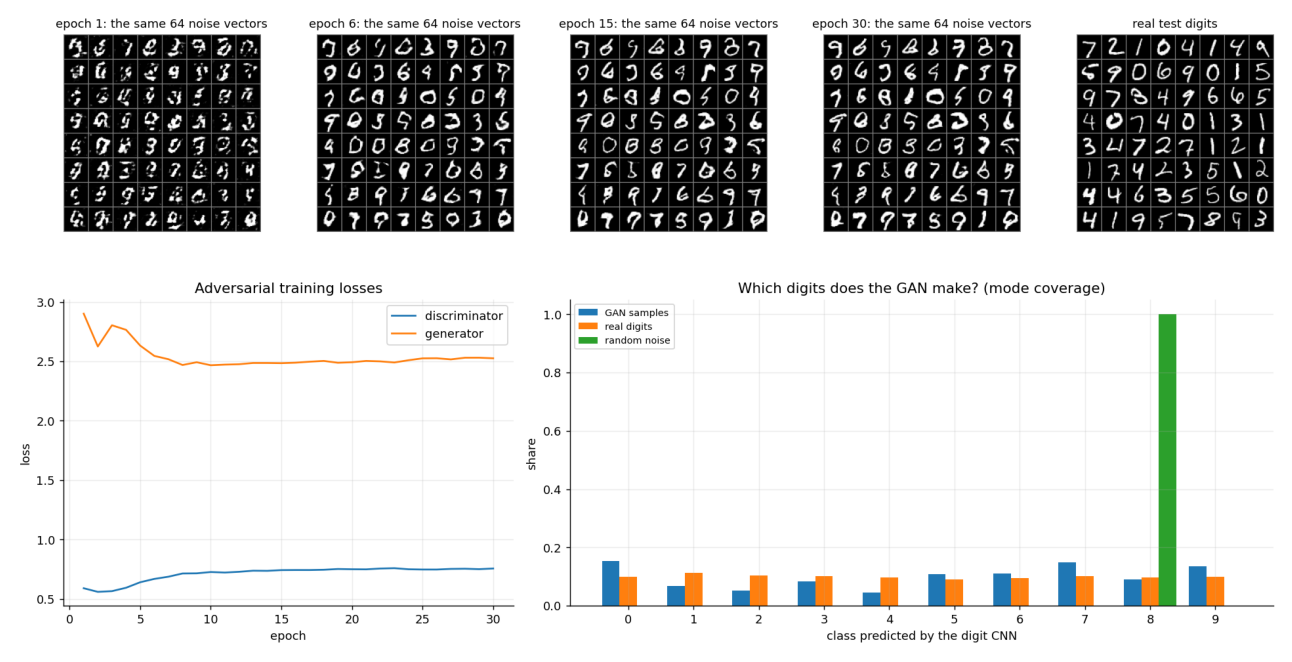

In [7]:
g = res('gan')
for k in ('real_test', 'generated', 'noise_baseline'): print(f"{k:<15}", {m: round(x, 3) for m, x in g[k].items() if m != 'class_share'})
show('gan')